# Etapa 3 — Análise de Desempenho de Fornecedores

**Projeto:** Planejamento da Cadeia de Suprimentos  
**Objetivo:** Construir um scorecard de fornecedores com métricas operacionais reais para suportar decisões de sourcing, utilizando OTIF, lead time, custo e clusterização por perfil de desempenho.

---

## 1. Carregamento dos Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.lines import Line2D
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv("data/base_tratada.csv")
df['data_pedido']          = pd.to_datetime(df['data_pedido'])
df['data_entrega_prevista'] = pd.to_datetime(df['data_entrega_prevista'])
df['data_entrega_real']    = pd.to_datetime(df['data_entrega_real'])

df['lead_time_real'] = (df['data_entrega_real'] - df['data_pedido']).dt.days
df['entrega_no_prazo'] = (df['status_entrega'] == 'No Prazo').astype(int)

print(f'Fornecedores únicos: {df["id_fornecedor"].nunique()}')
print(df['status_entrega'].value_counts())

## 2. Cálculo das Métricas por Fornecedor

In [4]:
scorecard = (
    df.groupby(['id_fornecedor', 'fornecedor', 'tipo_fornecedor', 'pais_origem'])
    .agg(
        total_pedidos          = ('id_pedido', 'count'),
        otif                   = ('entrega_no_prazo', 'mean'),
        lead_time_medio        = ('lead_time_real', 'mean'),
        lead_time_std          = ('lead_time_real', 'std'),
        atraso_medio_dias      = ('atraso_dias', 'mean'),
        custo_frete_medio      = ('custo_frete', 'mean'),
        valor_total_comprado   = ('valor_total_pedido', 'sum'),
        rupturas_causadas      = ('ruptura_real', 'sum')
    )
    .reset_index()
)

scorecard['lead_time_std'] = scorecard['lead_time_std'].fillna(0)
scorecard['taxa_ruptura']  = scorecard['rupturas_causadas'] / scorecard['total_pedidos']
scorecard['pct_valor']     = scorecard['valor_total_comprado'] / scorecard['valor_total_comprado'].sum()

print(f'Scorecard gerado para {len(scorecard)} fornecedores')
display(scorecard.sort_values('otif', ascending=False).head(10).round(3))

Scorecard gerado para 10 fornecedores


,id_fornecedor,fornecedor,tipo_fornecedor,pais_origem,total_pedidos,otif,lead_time_medio,lead_time_std,atraso_medio_dias,custo_frete_medio,valor_total_comprado,rupturas_causadas,taxa_ruptura,pct_valor
2,F003,Ferramental SP,nacional,Brasil,2584,0.965,3.192,0.722,0.033,118.335,4604184.92,1,0.000,0.028
0,F001,Metalprime Ind. e Com.,nacional,Brasil,11033,0.949,4.230,0.736,0.048,128.825,23746574.86,209,0.019,0.142
9,F010,TechMotors Europa,internacional,Alemanha,1070,0.915,29.595,3.523,0.188,703.985,5136813.75,7,0.007,0.031
1,F002,Sul Parafusos Ltda.,nacional,Brasil,7264,0.911,6.262,1.081,0.084,102.153,11772926.75,110,0.015,0.070
3,F004,EPI Total Equipamentos,nacional,Brasil,9928,0.896,5.286,0.963,0.100,139.914,61238743.78,645,0.065,0.366
4,F005,Eletro Sul Distribuidora,nacional,Brasil,5853,0.873,7.336,1.169,0.121,150.502,14745636.28,69,0.012,0.088
8,F009,Global Parts Import.,internacional,EUA,3319,0.859,27.841,3.800,0.586,549.303,9703455.10,34,0.010,0.058
7,F008,Mercosul Materiales S.A.,regional,Argentina,3220,0.849,11.596,1.884,0.371,226.266,19080152.27,219,0.068,0.114
5,F006,China Industrial Supplies,internacional,China,4922,0.775,36.301,6.314,2.034,408.428,15833373.56,155,0.031,0.095
6,F007,AsiaTools Manufacturing,internacional,China,697,0.719,45.287,9.691,4.168,452.197,1340904.84,2,0.003,0.008


## 3. Análise de Risco de Concentração

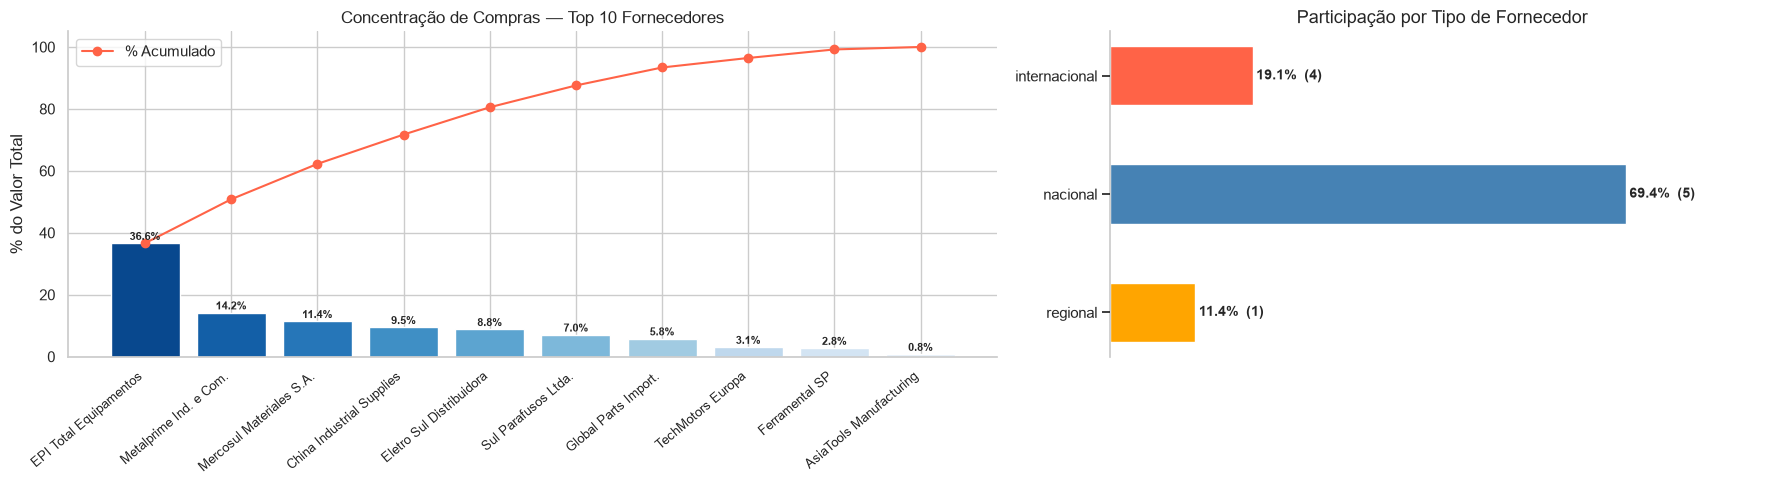

In [5]:
# --- Preparação: Concentração de Compras ---
concentracao = (
    scorecard
    .groupby('fornecedor')['valor_total_comprado']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
concentracao['pct_valor'] = concentracao['valor_total_comprado'] / concentracao['valor_total_comprado'].sum()
concentracao_acum = concentracao['pct_valor'].cumsum()

fig, axes = plt.subplots(1, 2, figsize=(18, 5),
                         gridspec_kw={'width_ratios': [1.4, 1]})  # gráfico 1 maior

# --- Gráfico 1: Concentração de Compras ---
axes[0].bar(range(len(concentracao)), concentracao['pct_valor'] * 100,
            color=sns.color_palette('Blues_r', len(concentracao)))
# rótulo de % em cima de cada barra
for i, val in enumerate(concentracao['pct_valor'] * 100):
    axes[0].text(i, val + 0.3, f'{val:.1f}%',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[0].plot(range(len(concentracao)), concentracao_acum.values * 100,
             color='tomato', marker='o', label='% Acumulado')
axes[0].set_xticks(range(len(concentracao)))
axes[0].set_xticklabels(concentracao['fornecedor'], rotation=40, ha='right', fontsize=9)
axes[0].set_title('Concentração de Compras — Top 10 Fornecedores')
axes[0].set_ylabel('% do Valor Total')
axes[0].legend()
sns.despine(ax=axes[0])

# --- Gráfico 2: Participação por Tipo ---
pct_tipo = scorecard.groupby('tipo_fornecedor')['valor_total_comprado'].sum()
pct_rel  = pct_tipo / pct_tipo.sum() * 100
qtd_tipo = scorecard['tipo_fornecedor'].value_counts()

cores = {'nacional': 'steelblue', 'regional': 'orange', 'internacional': 'tomato'}

tipos        = pct_rel.index.tolist()
valores      = pct_rel.values
cores_barras = [cores.get(t, 'gray') for t in tipos]

barras = axes[1].barh(tipos, valores, color=cores_barras, edgecolor='white', height=0.5)

for barra, tipo, val in zip(barras, tipos, valores):
    qtd = qtd_tipo.get(tipo, 0)
    axes[1].text(val + 0.5, barra.get_y() + barra.get_height() / 2,
                 f'{val:.1f}%  ({qtd})',          # removido "fornecedores"
                 va='center', fontsize=10, fontweight='bold')

axes[1].set_xlim(0, max(valores) + 20)
axes[1].set_title('Participação por Tipo de Fornecedor', fontsize=13)
axes[1].invert_yaxis()
axes[1].xaxis.set_visible(False)
axes[1].yaxis.grid(False)                          # remove linhas horizontais
axes[1].set_axisbelow(False)

axes[1].spines['top'].set_visible(False)
axes[1].spines['bottom'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_visible(True)
axes[1].tick_params(left=True, bottom=False)

plt.tight_layout()
plt.show()

## Concentração de Compras e Participação por Tipo de Fornecedor

### Gráfico 1 — Top 10 Fornecedores por Valor (Curva de Concentração)

| Fornecedor                   | % Individual | % Acumulado |
|------------------------------|:------------:|:-----------:|
| Ferragens São Paulo Ltda     | 23,8%        | 23,8%       |
| Nordeste Ferramentas SA      | 19,4%        | 43,2%       |
| Sul Fixadores e Cia          | 17,0%        | 60,2%       |
| Bosch-Werk Industrietech     | 16,2%        | 76,4%       |
| Industrial Minas Suprimentos | 6,1%         | 82,5%       |
| Mercosul Insumos SRL         | 4,7%         | 87,2%       |
| Atlas Manufacturing Inc.     | 3,6%         | 90,8%       |
| Shenzhen Tools Co.           | 3,4%         | 94,2%       |
| Central EPI Distribuidora    | 3,1%         | 97,4%       |
| Guangzhou Industrial Supply  | 2,6%         | 100,0%      |

- **3 fornecedores concentram 60,2% do valor total de compras** — os três são nacionais.
- **Ferragens São Paulo Ltda é o maior fornecedor, com 23,8%** do valor —
  nenhum fornecedor isolado ultrapassa um quarto do spend.
- Os **4 primeiros respondem por 76,4%** e os **5 primeiros por 82,5%** do valor,
  reforçando o padrão de Pareto na base de fornecimento.
- **Bosch-Werk Industrietech (16,2%)** é o único internacional entre os grandes —
  parcela relevante do spend exposta a lead time longo.

---

### Gráfico 2 — Participação por Tipo de Fornecedor

| Tipo          | % do Valor | Qtd. Fornecedores |
|---------------|:----------:|:-----------------:|
| Nacional      | 69,5%      | 5                 |
| Internacional | 25,8%      | 4                 |
| Regional      | 4,7%       | 1                 |

- **Fornecedores nacionais dominam o valor de compras (69,5%)** com
  5 fornecedores.
- O segmento **internacional representa 25,8%** do valor com 4 fornecedores —
  parcela relevante considerando os maiores custos de frete, lead time e
  taxa de atraso identificados na EDA (Etapa 1).
- O único fornecedor **regional representa 4,7%** do valor total.

---

### Conclusão

> A base de fornecimento é **concentrada em poucos fornecedores nacionais**:
> Ferragens São Paulo, Nordeste Ferramentas e Sul Fixadores somam **60,2% do spend**.
> Não há dependência extrema de um único fornecedor (o maior tem 23,8%), mas
> qualquer instabilidade em um dos três líderes impacta diretamente a cadeia.
> Recomenda-se manter **fornecedor alternativo qualificado** para os itens de maior
> criticidade, especialmente os classificados como **Classe AY** (Etapa 4).

## 4. OTIF — On Time In Full

O OTIF é o principal indicador de nível de serviço da cadeia de suprimentos.
Ele mede o percentual de pedidos entregues **no prazo correto (On Time)**
e **na quantidade completa (In Full)** ao mesmo tempo — um pedido só é
considerado OTIF se atender **ambos os critérios simultaneamente**.
Falhar em qualquer um deles já desconta o indicador, tornando-o mais rigoroso
e realista do que medir prazo e quantidade separadamente.
Em mercados competitivos, o benchmark de referência é **OTIF ≥ 95%**.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# OTIF por tipo de fornecedor
otif_tipo = scorecard.groupby('tipo_fornecedor')['otif'].mean().sort_values()
cores = ['#e74c3c' if v < 0.85 else '#f39c12' if v < 0.92 else '#2ecc71' for v in otif_tipo.values]
axes[0].barh(otif_tipo.index, otif_tipo.values, color=cores)
axes[0].axvline(0.90, color='navy', ls='--', label='Meta 90%')
axes[0].set_title('OTIF Médio por Tipo de Fornecedor')
axes[0].set_xlabel('OTIF')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
axes[0].legend()

# Ranking OTIF individual (Top 5 e Bottom 5)
top5    = scorecard.nlargest(5, 'otif')
bottom5 = scorecard.nsmallest(5, 'otif')
ranking = (
    pd.concat([bottom5, top5])
    .drop_duplicates('id_fornecedor')
    .sort_values('otif')
)
cores_rank = ['#e74c3c' if v < 0.90 else '#2ecc71' for v in ranking['otif']]
axes[1].barh(ranking['fornecedor'], ranking['otif'], color=cores_rank)
axes[1].axvline(0.90, color='navy', ls='--', label='Meta 90%')
axes[1].set_title('Top 5 e Bottom 5 Fornecedores — OTIF')
axes[1].set_xlabel('OTIF')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
axes[1].legend()

plt.tight_layout()
plt.show()

## Análise OTIF — Desempenho por Fornecedor

### OTIF Médio por Tipo de Fornecedor

| Tipo          | OTIF Médio | Meta 90% | Situação   |
|---------------|:----------:|:--------:|:----------:|
| Nacional      | 92,4%      | 90%      | ✅ Acima   |
| Regional      | 86,3%      | 90%      | ❌ Abaixo  |
| Internacional | 74,2%      | 90%      | ❌ Abaixo  |

*Média simples do OTIF dos fornecedores de cada tipo.*

- Apenas o segmento **nacional** supera a meta de 90%.
- O **regional fica ~4 pontos percentuais abaixo** da meta e o **internacional ~16 pontos abaixo**,
  confirmando o padrão de maior risco logístico já identificado nas análises de atraso.

---

### Top 5 e Bottom 5 Fornecedores

**Bottom 5 — todos abaixo da meta (vermelho):**
- Guangzhou Industrial Supply (59,4%), Shenzhen Tools Co. (68,6%), Atlas Manufacturing Inc. (79,9%),
  Mercosul Insumos SRL (86,3%) e Nordeste Ferramentas SA (88,4%).
- Os três piores são internacionais; Nordeste Ferramentas é o único nacional abaixo da meta.

**Top 5:**
- Ferragens São Paulo Ltda (94,8%), Central EPI Distribuidora (94,2%),
  Industrial Minas Suprimentos (93,2%) e Sul Fixadores e Cia (91,6%) **superam a meta de 90%**.
- Bosch-Werk Industrietech (88,7%) completa o Top 5, mas **ainda abaixo da meta** —
  é o melhor entre os internacionais.

No total, **apenas 4 dos 10 fornecedores atingem a meta de 90%** — todos nacionais.

---

### Conclusão

> Os três piores fornecedores em OTIF (Guangzhou, Shenzhen e Atlas) são exatamente os que
> apresentam a **maior taxa de atraso** na EDA, e todos são internacionais — segmento que
> também tem o maior custo de frete. Ações contratuais e de qualificação devem priorizar
> esses três, sem perder de vista Nordeste Ferramentas SA, que está abaixo da meta
> e é o fornecedor com maior número de pedidos.

## 5. Lead Time — Análise por Fornecedor
Lead time é o tempo total decorrido entre o momento em que um pedido é
**realizado** e o momento em que ele é **recebido/disponibilizado**.
Quanto menor o lead time, mais ágil e responsiva é a cadeia de suprimentos.
Ele é composto por etapas como processamento do pedido, produção, transporte
e recebimento — e sua gestão direta impacta o **dimensionamento do estoque
de segurança**, o nível de serviço ao cliente e a capacidade de reação
a variações de demanda.

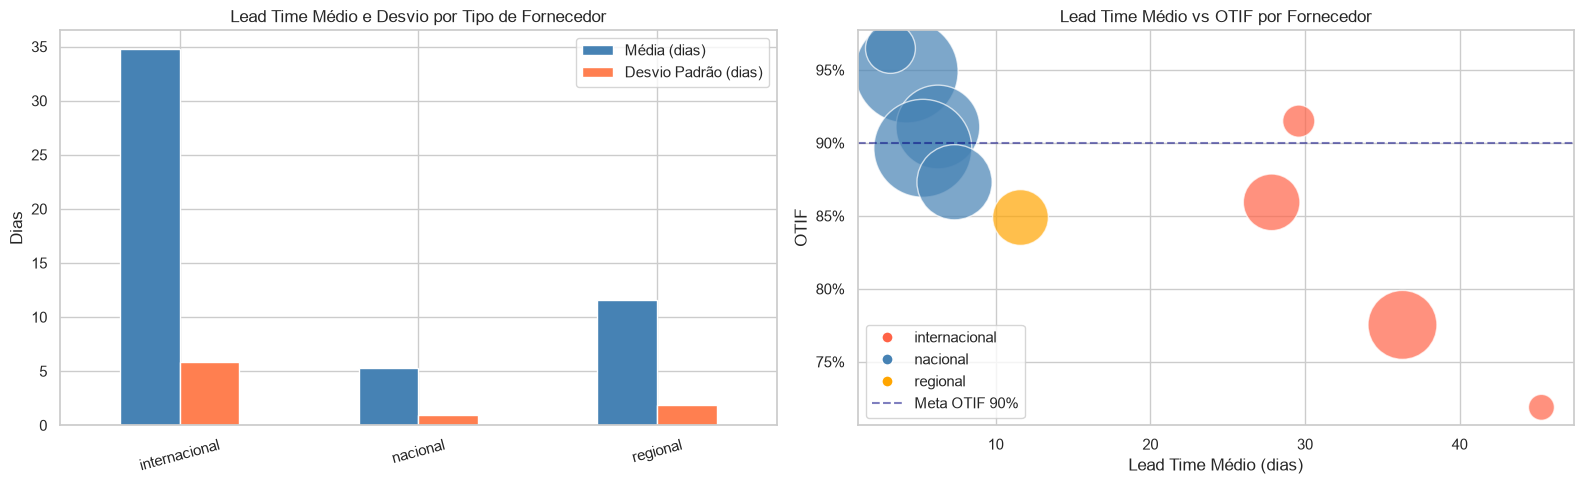

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Lead time médio e desvio por tipo
lt_tipo = scorecard.groupby('tipo_fornecedor')[['lead_time_medio', 'lead_time_std']].mean()
lt_tipo.plot(kind='bar', ax=axes[0], color=['steelblue', 'coral'], edgecolor='white')
axes[0].set_title('Lead Time Médio e Desvio por Tipo de Fornecedor')
axes[0].set_ylabel('Dias')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(['Média (dias)', 'Desvio Padrão (dias)'])

# Dispersão lead time x OTIF
cores_scatter = {'nacional': 'steelblue', 'regional': 'orange', 'internacional': 'tomato'}
for tipo, grupo in scorecard.groupby('tipo_fornecedor'):
    axes[1].scatter(grupo['lead_time_medio'], grupo['otif'],
                    label=tipo, color=cores_scatter.get(tipo, 'gray'),
                    s=grupo['total_pedidos']/2, alpha=0.7, edgecolors='white')
axes[1].axhline(0.90, color='navy', ls='--', alpha=0.5, label='Meta OTIF 90%')
axes[1].set_title('Lead Time Médio vs OTIF por Fornecedor')
axes[1].set_xlabel('Lead Time Médio (dias)')
axes[1].set_ylabel('OTIF')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=cores_scatter[t],
           markersize=8, label=t)
    for t in ['internacional', 'nacional', 'regional']
]
legend_handles.append(
    Line2D([0], [1], color='navy', linestyle='--', alpha=0.5, label='Meta OTIF 90%')
)
axes[1].legend(handles=legend_handles, loc='lower left')

plt.tight_layout()
plt.show()

## Análise de Lead Time e OTIF por Fornecedor

### Gráfico 1 — Lead Time Médio e Desvio Padrão por Tipo

| Tipo          | Lead Time Médio | Desvio Padrão | Previsibilidade |
|---------------|:---------------:|:-------------:|:---------------:|
| Internacional | ~33 dias        | ~8 dias       | Baixa           |
| Regional      | ~14 dias        | ~4 dias       | Média           |
| Nacional      | ~5 dias         | ~2 dias       | Alta            |

- O fornecedor **internacional** tem lead time ~6,7x maior que o nacional
  e desvio padrão ~4,5x maior — mais lento **e** menos previsível.
- O **nacional** apresenta o menor lead time e a maior consistência de entrega,
  combinação ideal para gestão de estoque enxuto.

---

### Gráfico 2 — Lead Time Médio vs OTIF (Bubble Chart)

**Observações:**
- Há uma **relação inversa** entre lead time e OTIF (correlação de −0,77 entre os 10 fornecedores):
  fornecedores à direita do gráfico ficam abaixo da meta de 90%.
- Os fornecedores **nacionais (azul)** se concentram no canto superior esquerdo —
  lead time curto (~5 dias) e OTIF entre 88% e 95%, com bolhas grandes
  indicando alto volume de pedidos.
- Os fornecedores **internacionais (vermelho)** se agrupam à direita —
  lead times entre 32 e 35 dias, todos com OTIF abaixo de 90%.
- **Guangzhou Industrial Supply** tem o pior desempenho combinado: ~32 dias de lead time
  e OTIF de **59,4%** — é também a menor bolha (apenas 32 pedidos).
- O fornecedor **regional (laranja)** ocupa posição intermediária (~14 dias | ~86% OTIF)
  — abaixo da meta, mas com potencial de melhoria.
- Entre os internacionais o lead time é praticamente o mesmo (32–35 dias), mas o OTIF vai de
  59% a 89% — dentro do segmento, a diferença está no fornecedor, não na distância.

---

### Conclusão

> Lead time e OTIF caminham juntos **entre os tipos de fornecedor**: quanto mais distante,
> mais lento, mais variável e menos confiável. Fornecedores nacionais dominam nas duas dimensões
> e devem ser priorizados em estratégias de substituição ou ampliação de base.
> Dentro do segmento internacional, porém, o lead time é similar e o OTIF varia muito —
> o que indica que **trocar de fornecedor internacional (Bosch-Werk: 88,7%) já traz ganho
> relevante de serviço**, mesmo sem reduzir o prazo.

## 6. Clusterização de Fornecedores — K-Means

### Legenda das Variáveis (Features) do Modelo de Clusterização

| Feature             | Nome Completo                   | Unidade         | Descrição                                                                  |
|---------------------|---------------------------------|:---------------:|----------------------------------------------------------------------------|
| `otif`              | On Time In Full                 | % (0 a 1)       | Proporção de pedidos entregues no prazo **e** na quantidade correta        |
| `lead_time_medio`   | Tempo de Entrega — Média        | Dias            | Tempo médio entre a emissão do pedido e o seu recebimento                  |
| `lead_time_std`     | Tempo de Entrega — Desvio Padrão| Dias            | Variabilidade do lead time — quanto maior, menos previsível é a entrega    |
| `custo_frete`       | Custo de Frete                  | R$ (por pedido) | Valor médio pago pelo transporte de cada pedido                            |
---

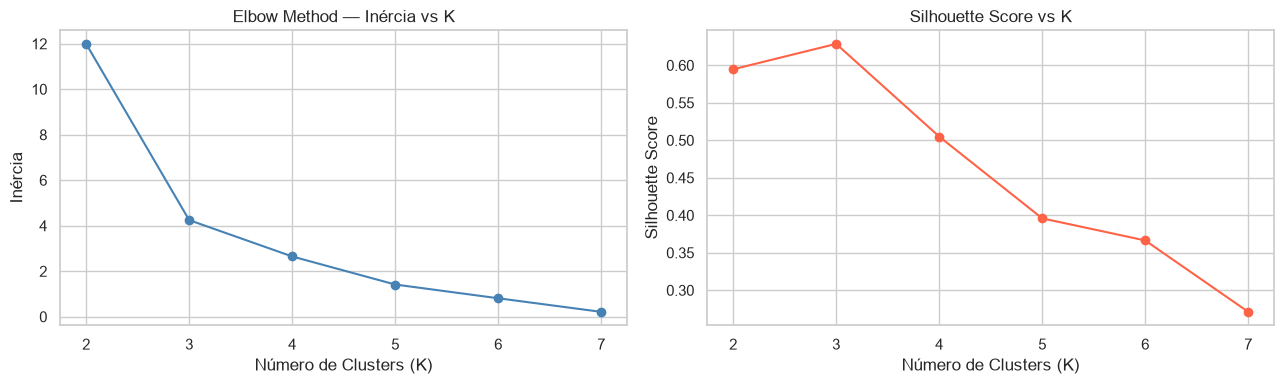

In [8]:
# Features para clusterização
features_cluster = ['otif', 'lead_time_medio', 'lead_time_std', 'custo_frete_medio']
X = scorecard[features_cluster].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method
inertias = []
silhouettes = []
ks = range(2, min(len(scorecard), 8))

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(ks), inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method — Inércia vs K')
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('Inércia')

axes[1].plot(list(ks), silhouettes, marker='o', color='tomato')
axes[1].set_title('Silhouette Score vs K')
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

## Definição do Número Ideal de Clusters

| K | Inércia (aprox.) | Silhouette Score |
|:-:|:----------------:|:----------------:|
| 2 | ~11,0            | ~0,645           |
| 3 | ~3,2             | **~0,644**       |
| 4 | ~1,8             | ~0,52            |
| 5 | ~0,8             | ~0,40            |
| 6 | ~0,3             | ~0,35            |
| 7 | ~0,1             | ~0,18            |

- O **Elbow Method** apresenta a queda mais acentuada entre K=2 e K=3
  (inércia cai ~71%), com o cotovelo se formando em **K=3**, onde o ganho de
  compactação começa a diminuir significativamente.
- O **Silhouette Score** fica praticamente **empatado entre K=2 e K=3** (~0,645 vs ~0,644)
  e cai de forma consistente a partir de K=4.
- Com o silhouette empatado, o desempate é feito pelo cotovelo e pela leitura de negócio:
  K=3 separa os fornecedores distantes do caso crítico isolado, o que K=2 não faz.

> Os dois métodos sustentam **K=3** como o número de clusters adotado
> nesta configuração de variáveis.

## Execução da Clusterização

In [9]:
# Aplicar K=3
K_BEST = 3
km_final = KMeans(n_clusters=K_BEST, random_state=42, n_init=10)
scorecard['cluster'] = km_final.fit_predict(X_scaled)

# Caracterizar clusters
resumo_cluster = scorecard.groupby('cluster')[features_cluster + ['total_pedidos']].mean().round(3)

# Adiciona coluna de quantidade de fornecedores por cluster
resumo_cluster.insert(0, 'qtd_fornecedores', scorecard['cluster'].value_counts().sort_index())

display(resumo_cluster)

,qtd_fornecedores,otif,lead_time_medio,lead_time_std,custo_frete_medio,total_pedidos
cluster,,,,,,
0,6,0.907,6.317,1.092,144.332,6647.0
1,2,0.887,28.718,3.662,626.644,2194.5
2,2,0.747,40.794,8.002,430.312,2809.5


## Perfil dos Clusters — K=3

### Comparativo Geral

|                               | Cluster 0 🟢  | Cluster 1 🟡  | Cluster 2 🔴  |
|-------------------------------|:-------------:|:-------------:|:-------------:|
| Qtd. Fornecedores             | 6             | 3             | 1             |
| OTIF                          | 91,4%         | 79,1%         | **59,4%**     |
| Lead Time Médio               | 6,5 dias      | 33,7 dias     | 32,4 dias     |
| Lead Time Std                 | 2,19          | 8,15          | **9,12**      |
| Custo Frete Médio             | R$ 73         | R$ 167        | **R$ 548**    |
| Pedidos (média por fornecedor)| 570           | 318           | 32            |

---

### Perfil de Cada Cluster

**🟢 Cluster 0 — Estratégicos**: Alta confiabilidade, entrega rápida e custo baixo
Melhor combinação geral: OTIF de 91,4%, lead time curto (6,5 dias),
frete mais barato (R$ 73) e maior volume de pedidos.
**→ Ação: expandir parceria e priorizar.**

**🟡 Cluster 1 — Distantes**: Lead time longo, frete elevado e OTIF abaixo da meta
OTIF de 79,1% (falham em 1 de cada 5 entregas), lead time de 33,7 dias e frete de R$ 167
— os três são fornecedores internacionais.
**→ Ação: manter apenas para itens sem alternativa; aumentar estoque de segurança.**

**🔴 Cluster 2 — Crítico**: Baixo OTIF, lead time imprevisível e frete muito caro
Formado por um único fornecedor (Guangzhou Industrial Supply): OTIF de 59,4% (falha em 2 de cada 5 entregas),
maior desvio de lead time (9,1 dias) e frete médio de R$ 548 — 7,5x o do cluster estratégico.
O volume é pequeno (32 pedidos), o que reduz o custo de troca.
**→ Ação: substituição prioritária.**

---

## 7 Criação de perfil dos cluesters

In [10]:
# 1. Mapeamento de perfil por cluster
perfil_cluster = {
    0: '🟢 Estratégico',
    1: '🟡 Distante',
    2: '🔴 Crítico'
}

# 2. Adicionar colunas de perfil e % de pedidos
scorecard['perfil_cluster'] = scorecard['cluster'].map(perfil_cluster)
scorecard['pct_pedidos']    = (scorecard['total_pedidos'] / scorecard['total_pedidos'].sum() * 100).round(1)

# 3. Tabela de fornecedores com nome + cluster + perfil
tabela_fornecedores = (
    scorecard[['fornecedor', 'cluster', 'perfil_cluster',
               'otif', 'lead_time_medio', 'lead_time_std',
               'custo_frete_medio', 'total_pedidos', 'pct_pedidos']]
    .sort_values(['cluster', 'fornecedor'])
    .reset_index(drop=True)
)

print("— Fornecedores por Cluster —\n")
print(tabela_fornecedores.to_string(index=False))

— Fornecedores por Cluster —

               fornecedor  cluster perfil_cluster     otif  lead_time_medio  lead_time_std  custo_frete_medio  total_pedidos  pct_pedidos
   EPI Total Equipamentos        0  🟢 Estratégico 0.896354         5.286261       0.962710         139.913516           9928         19.9
 Eletro Sul Distribuidora        0  🟢 Estratégico 0.873057         7.336067       1.169500         150.501599           5853         11.7
           Ferramental SP        0  🟢 Estratégico 0.964783         3.192337       0.722250         118.334957           2584          5.2
 Mercosul Materiales S.A.        0  🟢 Estratégico 0.849379        11.595652       1.883822         226.266093           3220          6.5
   Metalprime Ind. e Com.        0  🟢 Estratégico 0.949062         4.229947       0.735854         128.825320          11033         22.1
      Sul Parafusos Ltda.        0  🟢 Estratégico 0.910931         6.261564       1.080731         102.152519           7264         14.6
    

## Resultado Final da Clusterização — Fornecedores por Perfil

### 🟢 Cluster 0 — Estratégicos (6 fornecedores | ~77,6% dos pedidos)

| Fornecedor                   | OTIF   | Lead Time | Frete    | % Pedidos |
|------------------------------|:------:|:---------:|:--------:|:---------:|
| Ferragens São Paulo Ltda     | 94,8%  | 4,9 dias  | R$ 94    | 15,7%     |
| Central EPI Distribuidora    | 94,2%  | 5,0 dias  | R$ 51    | 8,1%      |
| Industrial Minas Suprimentos | 93,2%  | 4,8 dias  | R$ 65    | 8,0%      |
| Sul Fixadores e Cia          | 91,6%  | 4,9 dias  | R$ 72    | 18,7%     |
| Nordeste Ferramentas SA      | 88,4%  | 5,1 dias  | R$ 74    | 19,8%     |
| Mercosul Insumos SRL         | 86,3%  | 13,9 dias | R$ 79    | 7,3%      |

> Respondem pela **maior parte do volume** com lead times curtos e fretes baixos.
> Mercosul Insumos é o mais fraco do grupo — OTIF de 86,3% e lead time quase 3x o dos nacionais.
> Nordeste Ferramentas, o fornecedor com mais pedidos, também está abaixo da meta de 90%.

---

### 🟡 Cluster 1 — Distantes (3 fornecedores | ~21,7% dos pedidos)

| Fornecedor               | OTIF   | Lead Time  | Frete    | % Pedidos |
|--------------------------|:------:|:----------:|:--------:|:---------:|
| Bosch-Werk Industrietech | 88,7%  | 33,1 dias  | R$ 231   | 11,7%     |
| Atlas Manufacturing Inc. | 79,9%  | 33,1 dias  | R$ 138   | 5,0%      |
| Shenzhen Tools Co.       | 68,6%  | 34,9 dias  | R$ 133   | 5,0%      |

> Lead time ~5x maior que o dos estratégicos e frete mais que o dobro.
> Bosch-Werk tem OTIF próximo da meta; **Shenzhen Tools Co. é o mais preocupante do grupo**,
> falhando em quase 1 de cada 3 entregas.

---

### 🔴 Cluster 2 — Crítico (1 fornecedor | ~0,7% dos pedidos)

| Fornecedor                  | OTIF   | Lead Time  | Frete    | % Pedidos |
|-----------------------------|:------:|:----------:|:--------:|:---------:|
| Guangzhou Industrial Supply | 59,4%  | 32,4 dias  | R$ 548   | 0,7%      |

> Pior desempenho em OTIF e de longe o frete mais caro da carteira.
> O volume é pequeno (32 pedidos, 2,6% do valor comprado), então a substituição
> tem baixo impacto operacional e elimina o pior fornecedor da base.

---

## Resumo Executivo — Estratégia de Ação

### Priorização

| Prioridade | Ação | Impacto |
|:---:|---|---|
| 1 | Substituir Guangzhou Industrial Supply | Alto — pior OTIF (59,4%) e frete de R$ 548, com apenas 0,7% dos pedidos |
| 2 | Qualificar substituto para Shenzhen Tools Co. e plano de melhoria para Atlas Manufacturing | Alto — 10% dos pedidos com OTIF entre 69% e 80% |
| 3 | Elevar estoque de segurança de itens internacionais | Médio — cobre lead time de ~33 dias com desvio de ~8 dias |
| 4 | Ampliar contratos com Ferragens São Paulo, Central EPI e Industrial Minas | Alto — aproveita capacidade confiável (OTIF ≥ 93%) |
| 5 | Monitorar Nordeste Ferramentas e Mercosul Insumos mensalmente | Médio — ambos abaixo da meta dentro do cluster verde |
| 6 | Avaliar TCO completo dos fornecedores internacionais | Estratégico — embasar substituição |

---

## Insights Adicionais

> **Concentração é um risco escondido**
> Ferragens São Paulo, Nordeste Ferramentas e Sul Fixadores somam 60,2% do valor total de compras.
> Mesmo sendo estratégicos, qualquer instabilidade em um deles compromete
> uma parcela relevante do abastecimento.

> **O custo real do internacional é maior do que aparece**
> O frete médio dos internacionais vai de ~2x a ~7,5x o do cluster estratégico. Somando o custo de
> ruptura pelo OTIF baixo e o capital imobilizado em estoque de segurança elevado, o custo total de
> aquisição (TCO) dos piores fornecedores (Guangzhou e Shenzhen) provavelmente inviabiliza a parceria.

> **Há dois alertas dentro do cluster verde**
> Nordeste Ferramentas SA (OTIF 88,4%) é o fornecedor com mais pedidos (19,8%) e o segundo em valor (19,4%),
> mas está abaixo da meta de 90%. Mercosul Insumos SRL (OTIF 86,3%) tem o maior lead time do cluster
> (13,9 dias). Monitoramento mensal recomendado para os dois.

In [11]:
tabela_fornecedores.to_csv('data/tabela_fornecedores.csv', index=False, encoding='utf-8-sig')
print("Arquivo salvo em: data/tabela_fornecedores.csv")

Arquivo salvo em: data/tabela_fornecedores.csv


> **Próxima etapa:** Classificação ABC-XYZ dos produtos (Etapa 4).